In [1]:
cd ..

c:\Users\tangr\GitHub\pc-centrelines


Import the relevant modules

a = 000, b = 000, c = 000, d= 000

step 1. weigh 6 of the 12. 
either a < b  or a > b or a = b
step 2.
if a < b check a vs c. 
    if a < b and a == c, ball in b and heavier.
    elif a < b  and a < c, ball in a, and lighter 
elif a > b, check a vs c:
    if a > b and a == c, ball in b and lighter
    elif a > b and a > c, ball in a and heavier 
else: 
    a == b, check ??
    if a == b and a > c, ball in c and lighter
    if a == b and a < c, ball in c in heavier
    if a == b and a == c, ball in d

000 
000
xxx 
xxx


x x X egale, 
X x x 
x X x
xxxx xxxx xxxx

CCAA AaBB BBCC alors balance change de gauche à droite, on sait que Aa contient la boule.
ccaa aAbb bbcc la balance change de droite à gauche.
ccaa aaBb bbcc pas de changement, soit la balle dans les deux de droite de groupe 2 ou 3.
CCAA AAbB BBCC idem 
cCaa aabb bbcc d'équilibre à penche sur la gauche. la boule est cC, dans les deux à gauche.
CcAA AABB BBCC d'équilibre penche sur la droite, la boule est da 





In [2]:
# yaml processing file loading. 
import yaml
import numpy as np
import matplotlib.pyplot as plt
from os.path import exists, split, join, normpath, isdir
from os import listdir, makedirs

from stl import mesh
import pyvista as pv
# for the triangle adjacency matrix.
from base.utils import find_neighbours_with_knn
# for laplacian based contraction
from base.LBC_centreline import return_LBC_centreline
# for the iterative path finder
from base import iterative_section_minimiser
# for the maximum spanning tree clearance method
from base.MST_centreline import return_MST_centrelines


Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


Define some custom plotting styles.

In [3]:
with open(f"./notebooks/plot_kwargs.yaml", "r") as f: 
    p = yaml.safe_load(f)
    f.close()

In [4]:
skeleton_kwargs = p["skeleton_kwargs"]
node_kwargs = p["node_kwargs"]
ct_kwargs = p["ct_kwargs"]
ct_1_kwargs = p["ct1_kwargs"]
ct_2_kwargs = p["ct2_kwargs"]
mesh_kwargs = p["mesh_kwargs"]
start_kwargs = p["start_kwargs"]
end_kwargs = p["end_kwargs"]

Importing the mesh data. We work on the mesh vertices and triangles for the contraction of the pointcloud as well as the computation of mesh-plane intersections.

In [135]:
CONDUIT_NAME = "faux_monnayeurs"
ID = 10

In [136]:
## import the mesh data. 
mesh_fp =  f"./data/{ID}_{CONDUIT_NAME}/{CONDUIT_NAME}.stl"
data = mesh.Mesh.from_file(mesh_fp)
conduit = split(mesh_fp)[-1][:-4]
datatype = "real"
if "synthetic" in mesh_fp:
    datatype = "synthetic"
print(conduit)


faux_monnayeurs


We read the triangle adjacency matrix, and save it to a file for later retrieval, since this is a pre-computation step we only need to run once. We store it alongside the mesh data.

In [137]:
adj_triangles_fp = mesh_fp[:-4] + "_adjacent_triangles.txt"
if not exists(adj_triangles_fp):
    triangle_adjacency_matrix = find_neighbours_with_knn(data)
    np.savetxt(adj_triangles_fp, triangle_adjacency_matrix)
else: 
    triangle_adjacency_matrix = np.loadtxt(adj_triangles_fp)

Some preprocessing constants like are available on a yaml file associated with the data. 

In [138]:
with open(f"./data/{ID}_{CONDUIT_NAME}/{CONDUIT_NAME}_processing.yaml", "r") as f: 
    process_p = yaml.safe_load(f)
    f.close()

In [139]:
process_p

{'iterStepSize': 1,
 'axesPosition': [20, 4, 4],
 'hydraulic': False,
 'lbc': {'initAttraction': 2,
  'initContraction': 0.5,
  'voxelSize': 0.4,
  'downSample': 1},
 'mst': {'voxelSize': 0.4}}

## Centreline data from the hydraulic experiments

We load in memory the results from Ismail's experiments.

In [140]:
if process_p["hydraulic"]:

    hydraulic_ct_fp = f"./temp/{ID}_{CONDUIT_NAME}/hydraulic/{CONDUIT_NAME}_centreline.csv"
    hydraulic_ct = np.loadtxt(hydraulic_ct_fp, skiprows= 1, delimiter=",")
    DEMO_HYDRAULIC = True
else: 
    DEMO_HYDRAULIC = False

In [141]:
# hydraulic_ct_fp1 = f"./temp/{ID}_{CONDUIT_NAME}/hydraulic/{CONDUIT_NAME}_centreline.csv"
# hydraulic_ct[:, [1,2,3,4,5,6]] *=2
# np.savetxt(hydraulic_ct_fp1, hydraulic_ct, delimiter=",", fmt="%.6e", header  = "Iteration,comSimple_x,comSimple_y,comSimple_z,comVelWeighted_x,comVelWeighted_y,comVelWeighted_z,nNotExited,var_x,var_y,var_z")

In [142]:
DEMO_HYDRAULIC = False

In [143]:
if DEMO_HYDRAULIC == True:

    fig, ax = plt.subplots()
    # columns 1, 2 and 3 correspond to the first hydraulic centreline. 
    ax.plot(*hydraulic_ct[:, [1, 2]].T, **ct_1_kwargs)
    ax.plot(*hydraulic_ct[:, [1, 2]].T, **ct_1_kwargs)
    ax.scatter(*data.centroids[::20, [0, 1]].T, **mesh_kwargs)

    plt.savefig(f"./temp/{ID}_{CONDUIT_NAME}/hydraulic/{CONDUIT_NAME}_2d.pdf")
    plt.show()

    ## pyvista.
    pl = pv.Plotter() 
    # plot the mesh in 3d with pyvista.
    pv_mesh = pv.read(file_format="stl", filename=mesh_fp)
    _ = pl.add_mesh(pv_mesh, opacity = 0.25, label = f"mesh {CONDUIT_NAME}")

    pv_spline_1 = pv.Spline(hydraulic_ct[:, [1,2,3]], 500).tube(radius = 0.05)
    _ = pl.add_mesh(pv_spline_1, color = "firebrick", label = "centreline")
    axes = pv.AxesAssembly(position=process_p["axesPosition"], label_size = 9)
    _ = pl.add_actor(axes)
    pv.set_plot_theme('document')
    pl.set_viewup([0, 1, 0])

    legend = [{'label': f'mesh {CONDUIT_NAME}', 'color': 'teal', 'face': pv.Box()},
    {'label': 'centreline', 'color': 'firebrick', 'face': pv.Box()},
    ]

    pl.add_legend(legend)


    pl.save_graphic(f"./temp/{ID}_{CONDUIT_NAME}/hydraulic/{CONDUIT_NAME}_3d_top.pdf")
    pl.show()

    pl = pv.Plotter() 
    # plot the mesh in 3d with pyvista.
    pv_mesh = pv.read(file_format="stl", filename=mesh_fp)
    _ = pl.add_mesh(pv_mesh, opacity = 0.25, label = f"mesh {CONDUIT_NAME}")

    pv_spline_1 = pv.Spline(hydraulic_ct[:, [1,2,3]], 500).tube(radius = 0.05)
    _ = pl.add_mesh(pv_spline_1, color = "firebrick", label = "centreline")
    pv_spline_2 = pv.Spline(hydraulic_ct[:, [4,5,6]], 500).tube(radius = 0.05)
    _ = pl.add_mesh(pv_spline_2, color = "darkblue", label = "centreline")
    
    axes = pv.AxesAssembly(position=process_p["axesPosition"], label_size = 9)
    _ = pl.add_actor(axes)
    pv.set_plot_theme('document')

    legend = [{'label': f'mesh {CONDUIT_NAME}', 'color': 'teal', 'face': pv.Box()},
    {'label': 'centreline (uniform averaging)', 'color': 'firebrick', 'face': pv.Box()},
    {'label': 'centreline (flux weighted averaging)', 'color': 'darkblue', 'face': pv.Box()},
    ]

    pl.add_legend(legend)

    pl.save_graphic(f"./temp/{ID}_{CONDUIT_NAME}/hydraulic/{CONDUIT_NAME}_3d.pdf")
    pl.show()




## Centreline by laplacian-based contraction

We run the laplacian-based contraction algorithm.

In [144]:
lbc_centreline_fp = join(f"./temp/{ID}_{CONDUIT_NAME}/lbc/", f"{CONDUIT_NAME}_centreline.txt")

For demonstration purposes, we produce a figure containing the various stages of laplacian based contraction. 

In [145]:
from base.LBC_centreline import LBC
from base.utils import array_to_o3d

In [146]:
pcd = data.centroids
# convert to open3d object-
pcd = array_to_o3d(pcd)

In [147]:
DEMO_CONTRACTION = False

if DEMO_CONTRACTION == True:
    # initialise the list containing the stages of contraction. 
    skeleton_clouds = [] 
    for max_it_step in range(1,6):
        # set up the Laplacian-based contraction algorithm 
        lbc = LBC(point_cloud=pcd, 
                down_sample=process_p["lbc"]["voxelSize"],
                init_attraction = process_p["lbc"]["initAttraction"], 
                init_contraction = process_p["lbc"]["initContraction"], 
                max_iteration_steps=max_it_step)
        lbc.extract_skeleton()
        skeleton_clouds.append(lbc.contracted_point_cloud)


Now we plot the various stages of decomposition. 

In [148]:
if DEMO_CONTRACTION == True:
    fig, axes = plt.subplots(5, 2, figsize= (6.5, 8)) 

    # plot the first point cloud, before contraction. 
    axes[0, 0].scatter(*data.centroids[::75, [0, 1]].T, **skeleton_kwargs, label = "skeleton cloud\nbefore contraction")

    axes[0, 0].set_aspect("equal")
    axes[0, 0].set_xlabel("x")
    axes[0, 0].set_ylabel("y")

    axes[0, 1].scatter(*data.centroids[::75, [1, 2]].T, **skeleton_kwargs, label = "skeleton cloud\nbefore contraction")

    axes[0, 1].set_aspect("equal")
    axes[0, 1].set_xlabel("y")
    axes[0, 1].set_ylabel("z")

    k = 0
    for cloud, ax in zip(skeleton_clouds, axes[1:, 0]):
        k+=1
        the_pcd = np.asarray(cloud.points)
        ax.scatter(*the_pcd[:, [0, 1]].T, **skeleton_kwargs, label =f"skeleton cloud\nat contraction step {k}")
        ax.scatter(*data.centroids[::20, [0, 1]].T, **mesh_kwargs)
        
        ax.set_title(f"skeleton cloud at contraction step {k}", fontdict=dict(fontsize=9))
        ax.set_aspect("equal")
        ax.set_xlabel("x")
        ax.set_ylabel("y")

    k = 0
    for cloud, ax in zip(skeleton_clouds, axes[1:, 1]):
        k+=1
        the_pcd = np.asarray(cloud.points)
        ax.scatter(*the_pcd[:, [1, 2]].T, **skeleton_kwargs, label =f"skeleton cloud\nat contraction step {k}")
        ax.scatter(*data.centroids[::20, [1, 2]].T, **mesh_kwargs)
        
        ax.set_aspect("equal")
        ax.set_xlabel("y")
        ax.set_ylabel("z")

    axes[0, 0].set_title("skeleton cloud before contraction", fontdict=dict(fontsize=9))
    plt.tight_layout(pad = 2)
    plt.savefig(f"./temp/{ID}_{CONDUIT_NAME}/lbc/{CONDUIT_NAME}_lbc_contraction_steps.png", dpi = 300)
    plt.show()

In [149]:
# definition of processing metaparameters
lbc_args = dict(init_attraction = process_p["lbc"]["initAttraction"], 
                init_contraction = process_p["lbc"]["initContraction"],
                down_sample = process_p["lbc"]["voxelSize"])

ct_args = dict(keep = True, keep_centreline = False, centreline_down_sample = process_p["lbc"]["downSample"])

In [150]:
out_LBC = return_LBC_centreline(data,
                            ct_args= ct_args,
                            lbc_args= lbc_args)


read file in 0.0000s


2026-02-26 10:23:40,255 - PCD #points: 15900


contracted file in 3.1805s


Volume ratio: 0.37652328746471014. Contraction weights: 2048.0. Attraction weights: 82.25771000290044. Progress LBC:  20%|██        | 4/20 [00:11<00:47,  2.98s/it]2026-02-26 10:23:56,455 - Contraction is Done.
Volume ratio: 0.37652328746471014. Contraction weights: 2048.0. Attraction weights: 82.25771000290044. Progress LBC:  20%|██        | 4/20 [00:15<01:02,  3.88s/it]

Contraction is Done.
extracted skeleton in 16.3362s
downsampled the centreline cloud in 0.0016s
98
found largest component in 0.0011s
computed minimum spanning tree in 0.0144s
created graph instance of the centreline in  0.0006s
added node coordinates to graph in  0.0006s
this minimum spanning tree has 3 leaves. Need to identify the best path.


In [151]:
# we now save the cloud contracted centreline.
LBC_ct = out_LBC["sparse_cloud"][np.array(out_LBC["centreline"]).astype(int)]

np.savetxt(lbc_centreline_fp, LBC_ct, fmt= "%.6e")

In [152]:
# these are the source and target points. 
P1 = LBC_ct[0]
P2 = LBC_ct[-1]

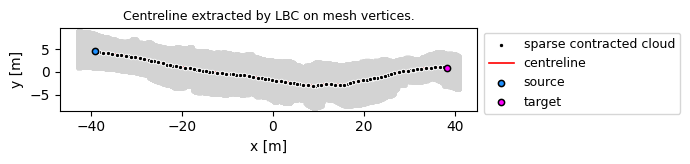

In [153]:
fig, ax = plt.subplots(figsize = (7, 5))

# plot the sparse cloud
ax.scatter(*out_LBC["sparse_cloud"][:, [0, 1]].T, 
           **node_kwargs, label = "sparse contracted cloud")

# plot the LBC estimate of the centreline 
ax.plot(*LBC_ct[:, [0, 1]].T,
        **ct_kwargs, label = "centreline")


# plot the start and end point
ax.scatter(*P1[[0, 1]],
           **start_kwargs)
ax.scatter(*P2[[0, 1]],
           **end_kwargs)

# plot the mesh 
ax.scatter(*data.centroids[::5, [0, 1]].T, 
           **mesh_kwargs)

# beautify the graph 
ax.set_aspect("equal")
ax.set_xlabel("x [m]")
ax.set_ylabel("y [m]")
ax.legend(fontsize = 9, bbox_to_anchor=(1, 1.02), loc = "upper left")
ax.set_title("Centreline extracted by LBC on mesh vertices.", fontdict=dict(fontsize=9))

plt.tight_layout()
plt.savefig(f"./temp/{ID}_{CONDUIT_NAME}/lbc/{CONDUIT_NAME}_lbc_contract.png", dpi = 300)

In [154]:
if DEMO_CONTRACTION == True:
    ## pyvista.
    pl = pv.Plotter() 
    # plot the mesh in 3d with pyvista.
    pv_mesh = pv.read(file_format="stl", filename=mesh_fp)
    _ = pl.add_mesh(pv_mesh, opacity = 0.25, label = f"mesh {CONDUIT_NAME}")

    pv_spline_1 = pv.Spline(LBC_ct[:, [0,1,2]], 500).tube(radius = 0.05)
    _ = pl.add_mesh(pv_spline_1, color = "firebrick", label = "centreline")
    axes = pv.AxesAssembly(position=process_p["axesPosition"], label_size = 9)
    _ = pl.add_actor(axes)

    _ = pl.add_points(LBC_ct[:, [0,1,2]],
                    render_points_as_spheres=True, 
                    point_size = 10.,
                    color = "k",
                    opacity=0.5)
    
    _ = pl.add_points(P1,
                    render_points_as_spheres=True, 
                    point_size = 20.,
                    color = "dodgerblue",
                    opacity=0.75, label = "source")
    _ = pl.add_points(P2,
                    render_points_as_spheres=True, 
                    point_size = 20.,
                    color = "fuchsia",
                    opacity=0.75, label = "target")

    pv.set_plot_theme('document')
    pl.set_viewup([0, 1, 0])


    pl.save_graphic(f"./temp/{ID}_{CONDUIT_NAME}/lbc/{CONDUIT_NAME}_3d_top.pdf")
    pl.show()

    pl = pv.Plotter() 
    # plot the mesh in 3d with pyvista.
    pv_mesh = pv.read(file_format="stl", filename=mesh_fp)
    _ = pl.add_mesh(pv_mesh, opacity = 0.25, label = f"mesh {CONDUIT_NAME}")

    pv_spline_1 = pv.Spline(LBC_ct[:, [0,1,2]], 500).tube(radius = 0.05)
    _ = pl.add_mesh(pv_spline_1, color = "firebrick", label = "centreline")

    _ = pl.add_points(P1,
                    render_points_as_spheres=True, 
                    point_size = 20.,
                    color = "dodgerblue",
                    opacity=0.75, label = "source")
    _ = pl.add_points(P2,
                    render_points_as_spheres=True, 
                    point_size = 20.,
                    color = "fuchsia",
                    opacity=0.75, label = "target")

    _ = pl.add_points(LBC_ct[:, [0,1,2]],
                    render_points_as_spheres=True, 
                    point_size = 10.,
                    color = "k",
                    opacity=0.5)

    axes = pv.AxesAssembly(position=process_p["axesPosition"], label_size = 9)
    _ = pl.add_actor(axes)
    pv.set_plot_theme('document')

    pl.save_graphic(f"./temp/{ID}_{CONDUIT_NAME}/lbc/{CONDUIT_NAME}_3d.pdf")
    pl.show()


Calling the voxelizer from Otfried. 

In [155]:
voxset_fp = mesh_fp[:-4] + "_voxset.vxl"

voxelsize = process_p["mst"]["voxelSize"]

out_MST = return_MST_centrelines(mesh_fp, voxset_path=voxset_fp, 
                             delta = int(voxelsize*1000), 
                             P1=P1, 
                             P2=P2, 
                             verbose = False)

Read 'c:\Users\tangr\OneDrive - unine.ch\ERCKarst\pc-centrelines\data\10_faux_monnayeurs\faux_monnayeurs_voxset.vxl': 1,237,314 vertices and 31,416 grid points,
Added edges in 6.0 sec.
Computed maximum spanning tree for clearance in 0.7 sec.
Computed path in maximum spanning tree in 0.1 sec.


Added edges in 0.1 sec.
Computed shortest path in 0.0 sec.


Polyline has 195 vertices
Simplified polyline has 34 vertices


Now we plot the demo figure showing not only the mesh, but its voxelised version, the centreline identified and the simplifications.

In [156]:
from matplotlib.colors import Normalize 
from matplotlib.cm import ScalarMappable
from matplotlib.gridspec import GridSpec

In [157]:
jagged_edges = np.loadtxt(f"temp/{ID}_{CONDUIT_NAME}/mst/{CONDUIT_NAME}_unzigzag_edges.xyz")
jagged_centreline = np.loadtxt(f"temp/{ID}_{CONDUIT_NAME}/mst/{CONDUIT_NAME}_{int(voxelsize*1000)}_jagged_centreline.txt")

In [158]:
mst_edges = np.loadtxt(f"temp/{ID}_{CONDUIT_NAME}/mst/{CONDUIT_NAME}_MST_edges.xyz")

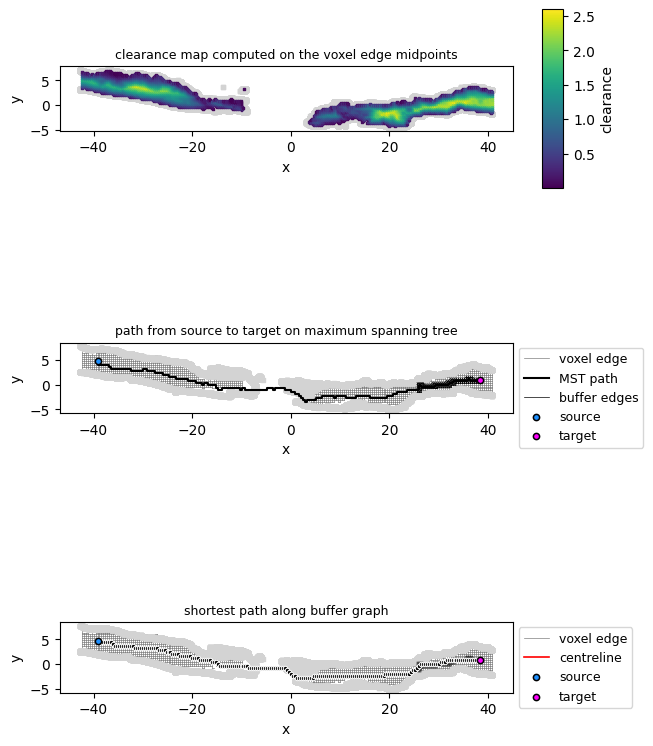

In [159]:
DEMO_MST = True

if DEMO_MST == True:
    
    edges = np.loadtxt(f"temp//{ID}_{CONDUIT_NAME}//mst//{CONDUIT_NAME}_edges.xyz")
    edges_mask = np.logical_and(edges[:, 2] == 0,edges[:, 5] == 0) 

    jagged_edges = np.loadtxt(f"temp//{ID}_{CONDUIT_NAME}//mst//{CONDUIT_NAME}_unzigzag_edges.xyz")
    jagged_edges_mask = np.logical_and(jagged_edges[:, 2] == 0,jagged_edges[:, 5] == 0) 

    mst_edges = np.loadtxt(f"temp//{ID}_{CONDUIT_NAME}//mst//{CONDUIT_NAME}_MST_edges.xyz")
    mst_edges_mask = np.logical_and(edges[:, 2] == 0,edges[:, 5] == 0) 

    vmin = np.min(edges[:, 6]/1000)
    vmax = np.max(edges[:, 6]/1000)

    norm = Normalize(vmin, vmax)
    mappable = ScalarMappable(norm)

    edges_midpoints = np.loadtxt(f"temp//{ID}_{CONDUIT_NAME}//mst//{CONDUIT_NAME}_edges_midpoints.xyz")

    gs = GridSpec(20, 20)
    fig = plt.figure(figsize = (6.5, 12))
    
    ax = fig.add_subplot(gs[0:4, :18])
    for edge, edge_mask in zip(edges, edges_mask):
        if edge_mask:
            ax.plot(edge[[0,3]],edge[[1,4]], color = "grey", zorder = -25, lw = 0.5)
    

    # plot the mesh 
    mesh_mask = np.abs(data.centroids[:, 2]) < 0.05
    ax.scatter(*data.centroids[mesh_mask][:, [0, 1]].T, 
            **mesh_kwargs)
    ax.set_title("clearance map computed on the voxel edge midpoints", fontdict= dict(fontsize=9))
    mask = np.abs(edges_midpoints[:, 2]) < 0.05
    ax.scatter(*edges_midpoints[mask][:, [0, 1]].T, c=edges_midpoints[mask, 3], zorder = -10, marker="s", s= 2)
    
    cax = fig.add_subplot(gs[0:4, 19:])
    cb = plt.colorbar(mappable, cax =cax, fraction=0.01)
    cb.set_label("clearance")
    ax.set_aspect("equal")


    ax.set_xlabel("x")
    ax.set_ylabel("y")


    ax = fig.add_subplot(gs[6:10, :18])
    for edge, edge_mask in zip(edges, edges_mask):
        if edge_mask:
            ax.plot(edge[[0,3]],edge[[1,4]], color = "grey", zorder = -25, lw = 0.5)
    ax.plot(edges[0,[0,3]],edges[0,[1,4]], color = "grey", zorder = -25, lw = 0.5, label ="voxel edge")
    
    # plot the mesh 
    mesh_mask = np.abs(data.centroids[:, 2]+0.5) < 0.05
    ax.scatter(*data.centroids[mesh_mask][:, [0, 1]].T, 
            **mesh_kwargs)
    
    
    ax.set_title("path from source to target on maximum spanning tree", fontdict= dict(fontsize=9))
    
    # plot the jagged centreline
    ax.plot(*jagged_centreline[:, [0, 1]].T, zorder = 100, color = "k", label = "MST path")
    ax.plot(*jagged_centreline[:, [0, 1]].T, zorder = 95, color = "white", lw = 1.5)
    
    for jagged_edge, jagged_edge_mask in zip(jagged_edges, jagged_edges_mask):
        if jagged_edge_mask:
            ax.plot(jagged_edge[[0,3]],jagged_edge[[1,4]], color = "k", zorder = -10, lw = 0.5)
    
    ax.plot(jagged_edges[0, [0,3]],jagged_edges[0, [1,4]], color = "k", zorder = -10, lw = 0.5, label ="buffer edges")
    

    # plot the source and target
    ax.scatter(*P1[[0, 1]],**start_kwargs)
    ax.scatter(*P2[[0, 1]], **end_kwargs)

    # define the colorbar for the mesh midpoints. 
    ax.legend(loc = "upper left", bbox_to_anchor= (1,1.02), fontsize = 9)
    ax.set_aspect("equal")

    ax.set_xlabel("x")
    ax.set_ylabel("y")

    ax = fig.add_subplot(gs[12:16, :18])
    for edge, edge_mask in zip(edges, edges_mask):
        if edge_mask:
            ax.plot(edge[[0,3]],edge[[1,4]], color = "grey", zorder = -20, lw = 0.5)
    ax.plot(edges[0,[0,3]],edges[0,[1,4]], color = "grey", zorder = -25, lw = 0.5, label ="voxel edge")

    
    # plot the centreline
    ax.plot(*np.array(out_MST["raw"])[:, [0, 1]].T,**ct_kwargs, label = "centreline")
    # plot the centreline nodes
    ax.scatter(*np.array(out_MST["raw"])[:, [0, 1]].T, 
           **node_kwargs)
    for jagged_edge, jagged_edge_mask in zip(jagged_edges, jagged_edges_mask):
        if jagged_edge_mask:
            ax.plot(jagged_edge[[0,3]],jagged_edge[[1,4]], color = "k", zorder = -10, lw = 0.25)
    
    
    ax.set_title("shortest path along buffer graph", fontdict= dict(fontsize=9))

    # plot the source and target
    ax.scatter(*P1[[0, 1]],**start_kwargs)
    ax.scatter(*P2[[0, 1]], **end_kwargs)


    # plot the mesh 
    mesh_mask = np.abs(data.centroids[:, 2]+0.5) < 0.05
    ax.scatter(*data.centroids[mesh_mask][:, [0, 1]].T, 
            **mesh_kwargs)
    
    ax.legend(loc="upper left", fontsize = 9, bbox_to_anchor=(1., 1.02))
    ax.set_aspect("equal")

    ax.set_xlabel("x")
    ax.set_ylabel("y")
    plt.savefig(f"./temp/{ID}_{CONDUIT_NAME}/mst/{CONDUIT_NAME}_edge_clearance_map.png", dpi = 300)
    plt.savefig(f"./temp/{ID}_{CONDUIT_NAME}/mst/{CONDUIT_NAME}_edge_clearance_map.pdf")

    plt.show()

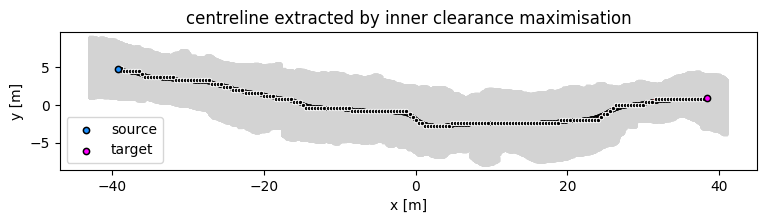

In [160]:
fig, ax = plt.subplots(figsize = (9, 5))

# plot the source and target
ax.scatter(*P1[[0, 1]],**start_kwargs)
ax.scatter(*P2[[0, 1]], **end_kwargs)

# plot the centreline
ax.plot(*np.array(out_MST["raw"])[:, [0, 1]].T,**ct_kwargs)
# plot the centreline nodes
ax.scatter(*np.array(out_MST["raw"])[:, [0, 1]].T, 
        **node_kwargs)

## the below can coincide with the raw centrespline if we're not careful. 
ax.plot(*np.array(out_MST["centerspline_direct"])[:, [0, 1]].T, "-o", markersize =2, color = "k")
#plt.plot(*np.array(out_MST["centerspline_fit1"])[:, [0, 1]].T, "-o", markersize =2, color = "b")

ax.set_title("centreline extracted by inner clearance maximisation")
ax.scatter(*data.centroids[::5, [0, 1]].T, **mesh_kwargs)
ax.set_aspect("equal")
ax.legend()
ax.set_xlabel("x [m]")
ax.set_ylabel("y [m]")

plt.savefig(f"./temp/{ID}_{CONDUIT_NAME}/mst/{CONDUIT_NAME}_extremities_MST_best_path.png", dpi = 300)


c:\Users\tangr\anaconda3\envs\pc-centreline\Lib\site-packages\pyvista\jupyter\notebook.py:56: UserWarning: Failed to use notebook backend: 

cannot import name 'vtk' from 'trame.widgets' (c:\Users\tangr\anaconda3\envs\pc-centreline\Lib\site-packages\trame\widgets\__init__.py)

Falling back to a static output.
  warnings.warn(


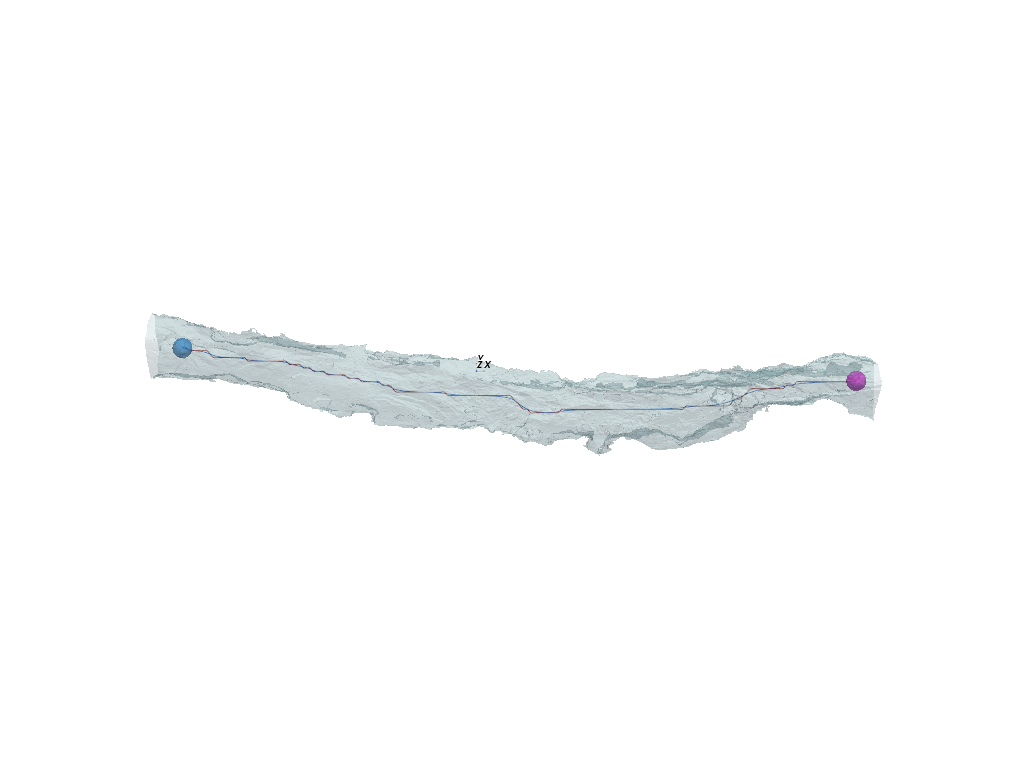

c:\Users\tangr\anaconda3\envs\pc-centreline\Lib\site-packages\pyvista\jupyter\notebook.py:56: UserWarning: Failed to use notebook backend: 

cannot import name 'vtk' from 'trame.widgets' (c:\Users\tangr\anaconda3\envs\pc-centreline\Lib\site-packages\trame\widgets\__init__.py)

Falling back to a static output.
  warnings.warn(


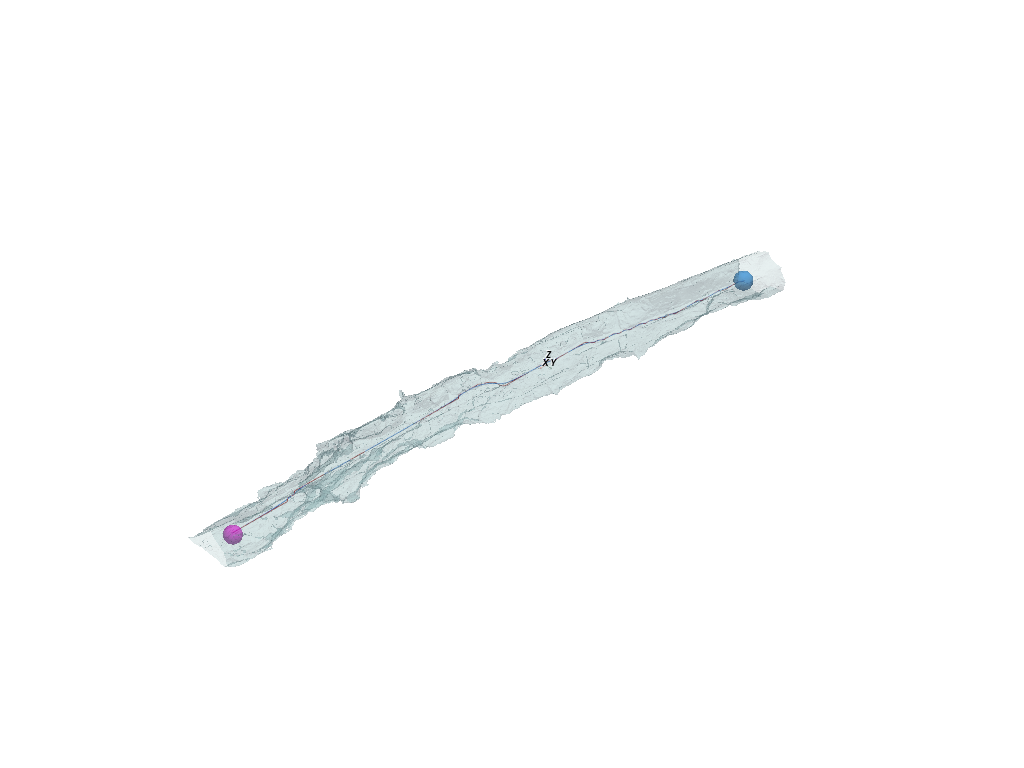

In [161]:
if DEMO_MST == True:
    ## pyvista.
    pl = pv.Plotter() 
    # plot the mesh in 3d with pyvista.
    pv_mesh = pv.read(file_format="stl", filename=mesh_fp)
    _ = pl.add_mesh(pv_mesh, opacity = 0.25, label = f"mesh {CONDUIT_NAME}")

    pv_spline_1 = pv.Spline(out_MST["raw"][:, [0,1,2]], 500).tube(radius = 0.05)
    _ = pl.add_mesh(pv_spline_1, color = "firebrick", label = "centreline")

    pv_spline_2 = pv.Spline(out_MST["centerspline_direct"][:, [0,1,2]], 500).tube(radius = 0.05)
    _ = pl.add_mesh(pv_spline_2, color = "dodgerblue", label = "centreline spline")
    axes = pv.AxesAssembly(position=(-5.0, 2.0, .0), label_size = 9)
    _ = pl.add_actor(axes)

    _ = pl.add_points(P1,
                    render_points_as_spheres=True, 
                    point_size = 20.,
                    color = "dodgerblue",
                    opacity=0.75, label = "source")
    _ = pl.add_points(P2,
                    render_points_as_spheres=True, 
                    point_size = 20.,
                    color = "fuchsia",
                    opacity=0.75, label = "target")


    pv.set_plot_theme('document')
    pl.set_viewup([0, 1, 0])


    pl.save_graphic(f"./temp/{ID}_{CONDUIT_NAME}/mst/{CONDUIT_NAME}_3d_top.pdf")
    pl.show()

    pl = pv.Plotter() 
    # plot the mesh in 3d with pyvista.
    pv_mesh = pv.read(file_format="stl", filename=mesh_fp)
    _ = pl.add_mesh(pv_mesh, opacity = 0.25, label = f"mesh {CONDUIT_NAME}")

    pv_spline_1 = pv.Spline(out_MST["raw"][:, [0,1,2]], 500).tube(radius = 0.05)
    _ = pl.add_mesh(pv_spline_1, color = "firebrick", label = "centreline")

    pv_spline_2 = pv.Spline(out_MST["centerspline_direct"][:, [0,1,2]], 500).tube(radius = 0.05)
    _ = pl.add_mesh(pv_spline_2, color = "dodgerblue", label = "centreline")

    _ = pl.add_points(P1,
                    render_points_as_spheres=True, 
                    point_size = 20.,
                    color = "dodgerblue",
                    opacity=0.75, label = "source")
    _ = pl.add_points(P2,
                    render_points_as_spheres=True, 
                    point_size = 20.,
                    color = "fuchsia",
                    opacity=0.75, label = "target")


    axes = pv.AxesAssembly(position=(-5.0, 2.0, .0), label_size = 9)
    _ = pl.add_actor(axes)
    pv.set_plot_theme('document')

    pl.save_graphic(f"./temp/{ID}_{CONDUIT_NAME}/mst/{CONDUIT_NAME}_3d.pdf")
    pl.show()


For the initial state of the iterative section minimiser, we have to find an initial normal vector. We use the neighbouring LBC centreline point and subtract to get a normal vector in an approximately optimal position.

In [36]:
nP0 = np.diff(LBC_ct[:2], axis =0)
nP0 /= np.linalg.norm(nP0)
np0 = nP0.flatten()

In the iterative section minimiser, we define the curvilinear distance of the LBC centreline as our expected centreline total curvilinear distance. We grow this expected distance by 5% to allow for extra tortuosity. This gives a natural upper bound of the number of iteration steps in our minimiser. 

In [37]:
L = np.sum(np.linalg.norm(np.diff(LBC_ct, axis =0), axis = 1))

In [38]:
process_p["iterStepSize"]

1

In [39]:
# if the iterative section minimiser has already been run, then, don't run and
# simply call it up again. 
iterative_ct_fp = join("./temp/", f"{ID}_{CONDUIT_NAME}/iterative/{CONDUIT_NAME}_centreline.txt") 
sections_fp = f"./temp/{ID}_{CONDUIT_NAME}/iterative/sections2d"
sections3d_fp = f"./temp/{ID}_{CONDUIT_NAME}/iterative/sections3d"
iterative_vectors_fp = join("./temp/", f"{ID}_{CONDUIT_NAME}/iterative/{CONDUIT_NAME}_vectors.txt") 

keep_iterative = False

if keep_iterative == True:
    out_iterative = {}
    out_iterative["centreline"] = np.loadtxt(iterative_ct_fp)
    out_iterative["vertices"] = []
    out_iterative["normals"] = np.loadtxt(iterative_vectors_fp)

    for section2d_name in listdir(sections_fp):
        section2d_fp = normpath(join(sections_fp, section2d_name))
        out_iterative["vertices"].append(np.loadtxt(section2d_fp))

else:

    out_iterative = iterative_section_minimiser.iterative_pathfinder(mesh_data=data,
                                                 P_start=P1,
                                                 nP0=nP0.flatten(),
                                                 P_end=P2, L=L, ds = process_p["iterStepSize"], eps= 0.001)
    
    
    np.savetxt(iterative_ct_fp, out_iterative["centreline"])
    np.savetxt(iterative_vectors_fp, out_iterative["normals"])

    # save the normals
    #for section2d in sections:
    # save the 2d sections
    if not isdir(sections_fp):
        makedirs(sections_fp)
    for k, section in enumerate(out_iterative["vertices"]):
            np.savetxt(join(sections_fp, f"s2d_{k}.txt"), section)

 87%|████████▋ | 84/97.0 [14:03<02:10, 10.05s/it]


We can finally extract the centreline from this process.

In [40]:
iterative_ct = out_iterative["centreline"]

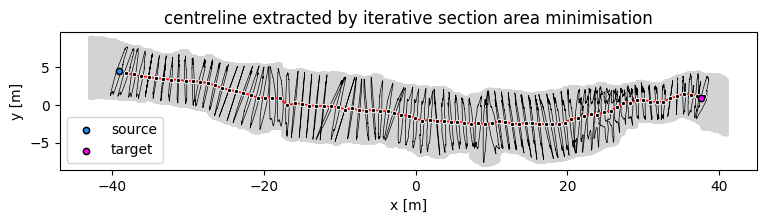

In [41]:
fig, ax = plt.subplots(figsize = (9, 5))
ax.scatter(*P1[[0, 1]],**start_kwargs)
ax.scatter(*P2[[0, 1]], **end_kwargs)

ax.scatter(*data.centroids[::5, [0, 1]].T, **mesh_kwargs)
ax.scatter(*out_iterative["centreline"][:, [0, 1]].T, 
           **node_kwargs)

ax.plot(*out_iterative["centreline"][:, [0, 1]].T, **ct_kwargs)

for vertex_set in out_iterative["vertices"]:
    ax.plot(*vertex_set[:, [0, 1]].T, color = "k", lw = 0.5)

## example for the ending criterion- needs to be within epsilon of plane and within d of the barycentre of section.
## if both are good, then stop!

ax.set_title("centreline extracted by iterative section area minimisation")
ax.set_xlabel("x [m]")
ax.set_ylabel("y [m]")
ax.set_aspect("equal")
ax.legend()

plt.savefig(f"./temp/{ID}_{CONDUIT_NAME}/iterative/{CONDUIT_NAME}_extremities_iterative_pathfinder.png", dpi = 300)
plt.savefig(f"./temp/{ID}_{CONDUIT_NAME}/iterative/{CONDUIT_NAME}_extremities_iterative_pathfinder.pdf")



In [42]:
DEMO_ITERATIVE = True

c:\Users\tangr\anaconda3\envs\pc-centreline\Lib\site-packages\pyvista\jupyter\notebook.py:56: UserWarning: Failed to use notebook backend: 

cannot import name 'vtk' from 'trame.widgets' (c:\Users\tangr\anaconda3\envs\pc-centreline\Lib\site-packages\trame\widgets\__init__.py)

Falling back to a static output.
  warnings.warn(


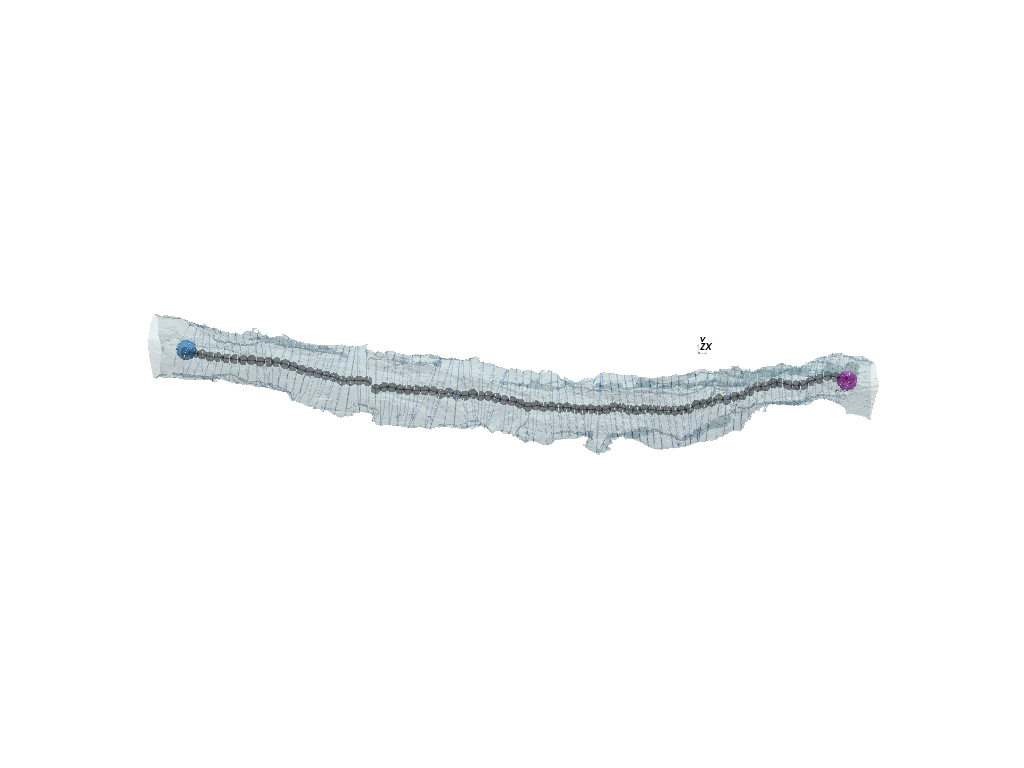

c:\Users\tangr\anaconda3\envs\pc-centreline\Lib\site-packages\pyvista\jupyter\notebook.py:56: UserWarning: Failed to use notebook backend: 

cannot import name 'vtk' from 'trame.widgets' (c:\Users\tangr\anaconda3\envs\pc-centreline\Lib\site-packages\trame\widgets\__init__.py)

Falling back to a static output.
  warnings.warn(


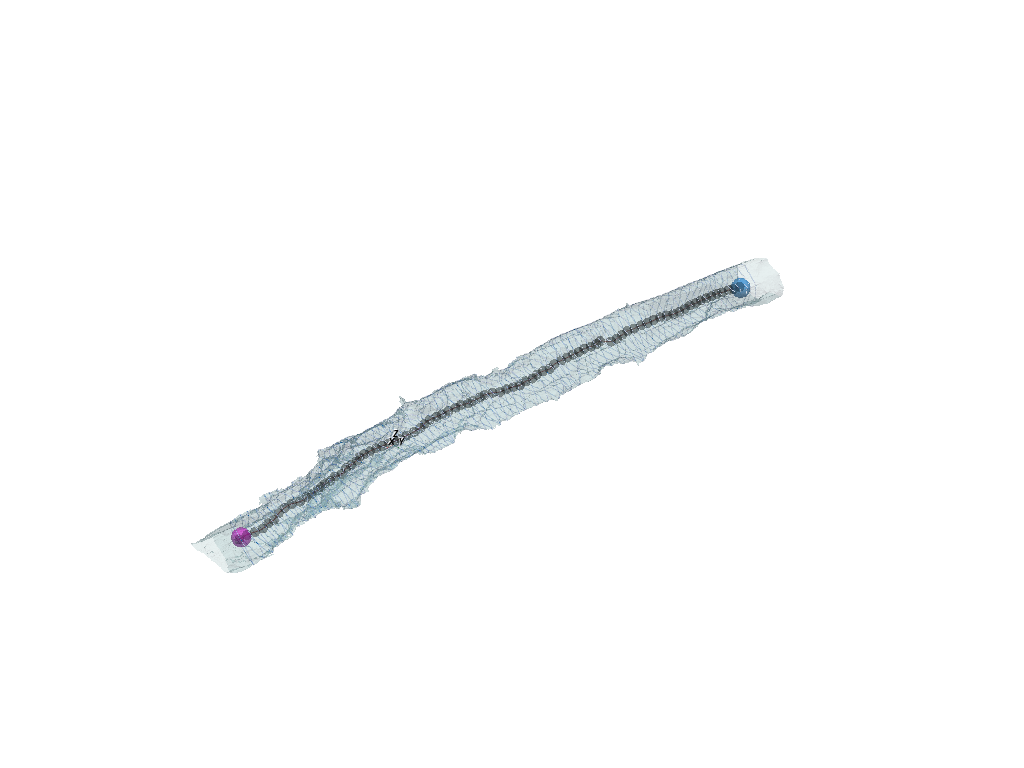

In [43]:
if DEMO_ITERATIVE == True:
    ## pyvista.
    pl = pv.Plotter() 
    # plot the mesh in 3d with pyvista.
    pv_mesh = pv.read(file_format="stl", filename=mesh_fp)
    _ = pl.add_mesh(pv_mesh, opacity = 0.25, label = f"mesh {CONDUIT_NAME}")

    pv_spline_1 = pv.Spline(out_iterative["centreline"][:, [0,1,2]], 500).tube(radius = 0.05)
    _ = pl.add_mesh(pv_spline_1, color = "firebrick", label = "centreline")
    axes = pv.AxesAssembly(position=process_p["axesPosition"], label_size = 9)
    _ = pl.add_actor(axes)

    _ = pl.add_points(out_iterative["centreline"][:, [0,1,2]],
                    render_points_as_spheres=True, 
                    point_size = 10.,
                    color = "k",
                    opacity=0.5)
    
    _ = pl.add_points(P1,
                    render_points_as_spheres=True, 
                    point_size = 20.,
                    color = "dodgerblue",
                    opacity=0.75, label = "source")
    _ = pl.add_points(P2,
                    render_points_as_spheres=True, 
                    point_size = 20.,
                    color = "fuchsia",
                    opacity=0.75, label = "target")

    for vertex_set in out_iterative["vertices"]:
        pv_spline = pv.Spline(vertex_set[:, [0,1,2]], 500).tube(radius = 0.025)
        _ = pl.add_mesh(pv_spline, color = "dodgerblue")    

    pv.set_plot_theme('document')
    pl.set_viewup([0, 1, 0])


    pl.save_graphic(f"./temp/{ID}_{CONDUIT_NAME}/iterative/{CONDUIT_NAME}_3d_top.pdf")
    pl.show()

    pl = pv.Plotter() 
    # plot the mesh in 3d with pyvista.
    pv_mesh = pv.read(file_format="stl", filename=mesh_fp)
    _ = pl.add_mesh(pv_mesh, opacity = 0.25, label = f"mesh {CONDUIT_NAME}")

    pv_spline_1 = pv.Spline(out_iterative["centreline"][:, [0,1,2]], 500).tube(radius = 0.05)
    _ = pl.add_mesh(pv_spline_1, color = "firebrick", label = "centreline")

    _ = pl.add_points(out_iterative["centreline"][:, [0,1,2]],
                    render_points_as_spheres=True, 
                    point_size = 10.,
                    color = "k",
                    opacity=0.5)
    
    _ = pl.add_points(P1,
                    render_points_as_spheres=True, 
                    point_size = 20.,
                    color = "dodgerblue",
                    opacity=0.75, label = "source")
    _ = pl.add_points(P2,
                    render_points_as_spheres=True, 
                    point_size = 20.,
                    color = "fuchsia",
                    opacity=0.75, label = "target")
    

    for vertex_set in out_iterative["vertices"]:
        pv_spline = pv.Spline(vertex_set[:, [0,1,2]], 500).tube(radius = 0.025)
        _ = pl.add_mesh(pv_spline, color = "dodgerblue")    

    axes = pv.AxesAssembly(position=process_p["axesPosition"], label_size = 9)
    _ = pl.add_actor(axes)
    pv.set_plot_theme('document')

    pl.save_graphic(f"./temp/{ID}_{CONDUIT_NAME}/iterative/{CONDUIT_NAME}_3d.pdf")
    pl.show()


Now we can make a comparison of all four / five methods for a paper figure. 

C:\Users\tangr\AppData\Local\Temp\ipykernel_6152\300457800.py:69: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
C:\Users\tangr\AppData\Local\Temp\ipykernel_6152\300457800.py:70: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.savefig(f"./temp/{ID}_{CONDUIT_NAME}/{CONDUIT_NAME}_centreline_comparisons.png", dpi = 300)
c:\Users\tangr\anaconda3\envs\pc-centreline\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


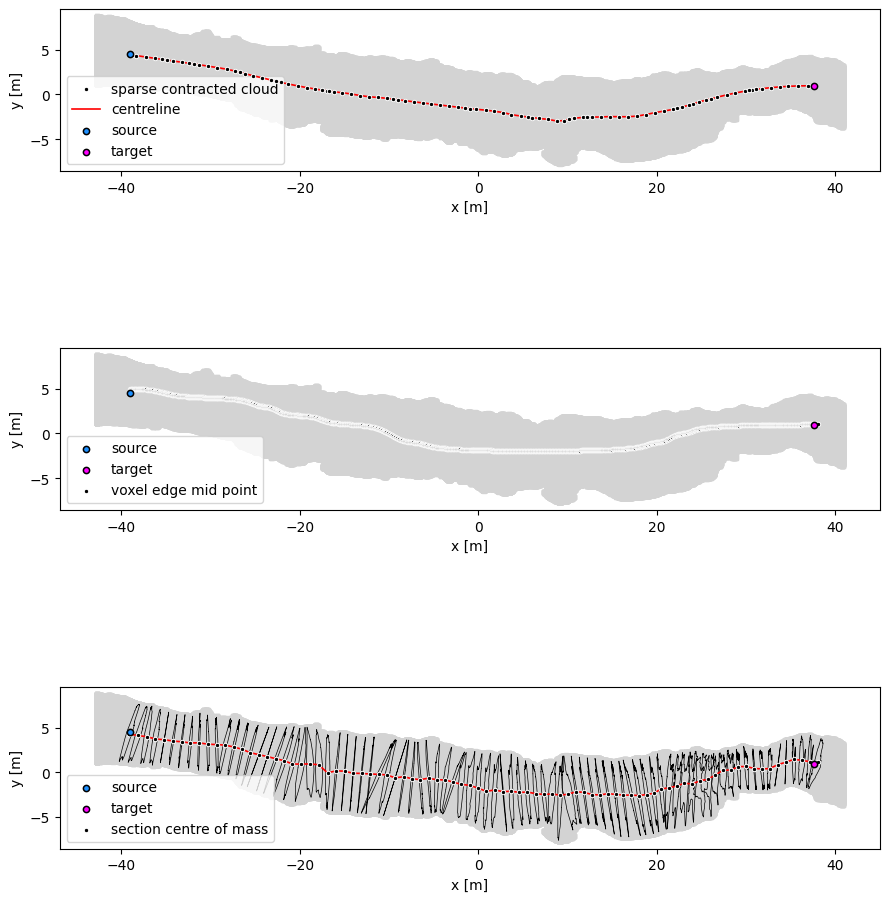

In [44]:
fig, axes = plt.subplots(3, 1, figsize = (9, 11))
## laplacian based contraction 
ax  = axes[0]
# plot the sparse cloud
ax.scatter(*out_LBC["sparse_cloud"][:, [0, 1]].T, 
           **node_kwargs, label = "sparse contracted cloud")

# plot the LBC estimate of the centreline 
ax.plot(*LBC_ct[:, [0, 1]].T,
        **ct_kwargs, label = "centreline")

# plot the start and end point
ax.scatter(*P1[[0, 1]],
           **start_kwargs)
ax.scatter(*P2[[0, 1]],
           **end_kwargs)

# plot the mesh 
ax.scatter(*data.centroids[::5, [0, 1]].T, 
           **mesh_kwargs)

# beautify the graph 
ax.set_aspect("equal")
ax.set_xlabel("x [m]")
ax.set_ylabel("y [m]")
ax.legend(fontsize = 10)

## maximum spanning tree. 
ax = axes[1]
# plot the source and target
ax.scatter(*P1[[0, 1]],**start_kwargs)
ax.scatter(*P2[[0, 1]], **end_kwargs)

# plot the centreline
ax.plot(*np.array(out_MST["centerspline_direct"])[:, [0, 1]].T,**ct_kwargs)
# plot the centreline nodes
ax.scatter(*np.array(out_MST["centerspline_direct"])[:, [0, 1]].T, 
           **node_kwargs, label = "voxel edge mid point")

## the below can coincide with the raw centrespline if we're not careful. 
#ax.plot(*np.array(out_MST["centerspline_direct"])[:, [0, 1]].T, "-o", markersize =2, color = "k")
#plt.plot(*np.array(out_MST["centerspline_fit-simplified"])[:, [0, 1]].T, "-o", markersize =2, color = "r")
#plt.plot(*np.array(out_MST["centerspline_fit1"])[:, [0, 1]].T, "-o", markersize =2, color = "b")

ax.scatter(*data.centroids[::5, [0, 1]].T, **mesh_kwargs)
ax.set_aspect("equal")
ax.set_xlabel("x [m]")
ax.set_ylabel("y [m]")
ax.legend(fontsize=10)

## iterative. 
ax = axes[2]
ax.scatter(*P1[[0, 1]],**start_kwargs)
ax.scatter(*P2[[0, 1]], **end_kwargs)

ax.scatter(*data.centroids[::5, [0, 1]].T, **mesh_kwargs)
ax.scatter(*out_iterative["centreline"][:, [0, 1]].T, 
           **node_kwargs, label = "section centre of mass")

ax.plot(*out_iterative["centreline"][:, [0, 1]].T, **ct_kwargs)

for vertex_set in out_iterative["vertices"]:
    ax.plot(*vertex_set[:, [0, 1]].T, color = "k", lw = 0.5)

ax.set_xlabel("x [m]")
ax.set_ylabel("y [m]")
ax.set_aspect("equal")
ax.legend(fontsize=10)
plt.tight_layout()
plt.savefig(f"./temp/{ID}_{CONDUIT_NAME}/{CONDUIT_NAME}_centreline_comparisons.png", dpi = 300)

## Comparing the various centrelines

In [ ]:
# find on the hydraulic lines the start and end points. 

In [ ]:
def find_hydraulic_start_end(hydraulic, P1, P2):
    idx_p1 = np.argmin(np.linalg.norm((hydraulic - P1), axis = 1))
    idx_p2 = np.argmin(np.linalg.norm((hydraulic - P2), axis = 1))
    if idx_p1 < idx_p2:
        return hydraulic[idx_p1:idx_p2]
    else:
        return hydraulic[idx_p2:idx_p1]

In [ ]:
hydraulic_1_ct_trimmed = find_hydraulic_start_end(hydraulic_ct[:, [1,2,3]], P1, P2)
hydraulic_2_ct_trimmed = find_hydraulic_start_end(hydraulic_ct[:, [4,5,6]], P1, P2)

In [ ]:
MST_ct = np.array(out_MST["raw"])

In [ ]:
fig, ax = plt.subplots()

ax.plot(*hydraulic_1_ct_trimmed[:, [0,1]].T, **ct_1_kwargs)
ax.plot(*hydraulic_2_ct_trimmed[:, [0,1]].T, **ct_2_kwargs)
ax.plot(*MST_ct[:, [0,1]].T, **ct_kwargs)
ax.plot(*LBC_ct[:, [0,1]].T, **ct_kwargs)
ax.plot(*iterative_ct[:, [0,1]].T, **ct_kwargs)

#ax.scatter(*data.centroids[::100,[0,1]].T, **mesh_kwargs)

#ax.set_aspect("equal")


we use the Fréchet distance to measure how accurate each centreline is to the geometric centreline expected for synthetic conduits. 

In [ ]:
from base.frechet_dist import frdist

In [ ]:
from scipy.interpolate import interp1d

In [ ]:

def parametrise_ct(ct):
    t = np.zeros(ct.shape[0])
    cumsum = np.cumsum(np.linalg.norm(np.diff(ct, axis = 0), axis = 1))
    L = np.max(cumsum)
    t[1:] =  cumsum / L

    x_interp  = interp1d(t, ct[:,  0])
    y_interp  = interp1d(t, ct[:,  1])
    z_interp  = interp1d(t, ct[:,  2])

    return x_interp, y_interp, z_interp


In [ ]:
def dis_fr_dist(ct1, ct2, npoints= 200):
    ti = np.linspace(0, 1, npoints)
    x1, y1, z1 = parametrise_ct(ct1)
    x2, y2, z2 = parametrise_ct(ct2)

    poly1 = np.vstack([x1(ti), y1(ti), z1(ti)]).T
    poly2 = np.vstack([x2(ti), y2(ti), z2(ti)]).T

    return frdist(poly1, poly2)

In [ ]:
def summarise_fr_metric(hyd_ct_1, hyd_ct_2, lbc_ct, mst_ct, iterative_ct):
    fr_hyd_1_hyd_2 = dis_fr_dist(hyd_ct_1, hyd_ct_2)
    fr_hyd_1_lbc = dis_fr_dist(hyd_ct_1, lbc_ct)
    fr_hyd_2_lbc = dis_fr_dist(hyd_ct_2, lbc_ct)
    fr_hyd_1_mst = dis_fr_dist(hyd_ct_1, mst_ct)
    fr_hyd_2_mst = dis_fr_dist(hyd_ct_2, mst_ct)
    fr_hyd_1_it = dis_fr_dist(hyd_ct_1, iterative_ct)
    fr_hyd_2_it = dis_fr_dist(hyd_ct_2, iterative_ct)

    return fr_hyd_1_hyd_2, fr_hyd_1_lbc, fr_hyd_2_lbc, fr_hyd_1_mst, fr_hyd_2_mst, fr_hyd_1_it, fr_hyd_2_it

In [ ]:
names =  ["fr_hyd_1_hyd_2",
    "fr_hyd_1_lbc",
    "fr_hyd_2_lbc",
    "fr_hyd_1_mst",
    "fr_hyd_2_mst",
    "fr_hyd_1_it",
    "fr_hyd_2_it"]

In [ ]:
fr_summary = summarise_fr_metric(hydraulic_1_ct_trimmed, hydraulic_2_ct_trimmed, LBC_ct, MST_ct, iterative_ct)

In [ ]:
fr_summary

In [ ]:
fr_fp = f"./temp/{ID}_{CONDUIT_NAME}/{CONDUIT_NAME}_summary.txt"
with open(fr_fp, "w") as f:
    for name, elem in zip(names, fr_summary):
        f.write(f"{name}, {elem:.5f}\n")

    f.close()